In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt


## Контрольная работа 4 Вариант 2

### Задача 1 Численное дифференцирование (1.5 балла)

Для заданной функции $f(x)=c h(x)$ на интервале $[-1 ; 0]$ для нескольких шагов $h$
- Аналитически рассчитать вторую производную 
- Вычислить и построить аппроксимацию второй производной, используя схемы первого и второго порядка аппроксимации, построить графики вместе с истинным ответом для одного из значений $h$
- Вычислить и погрешность для каждой из аппроксимаций и построить её от шага $h$. Какие получились экспериментальные порядки аппроксимации?

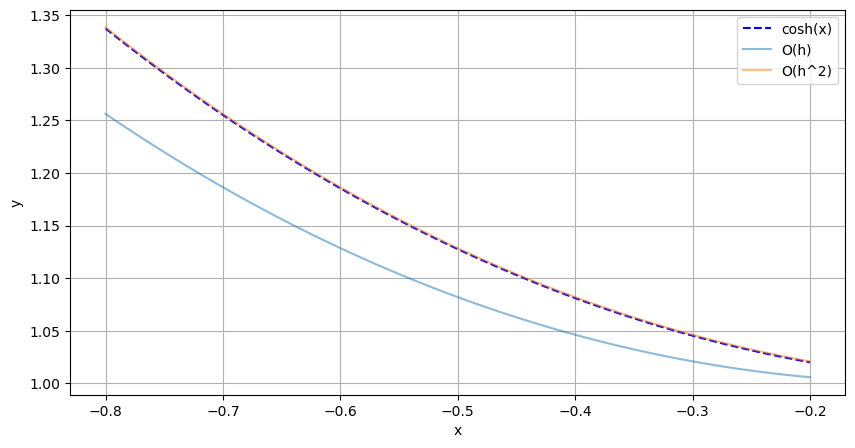

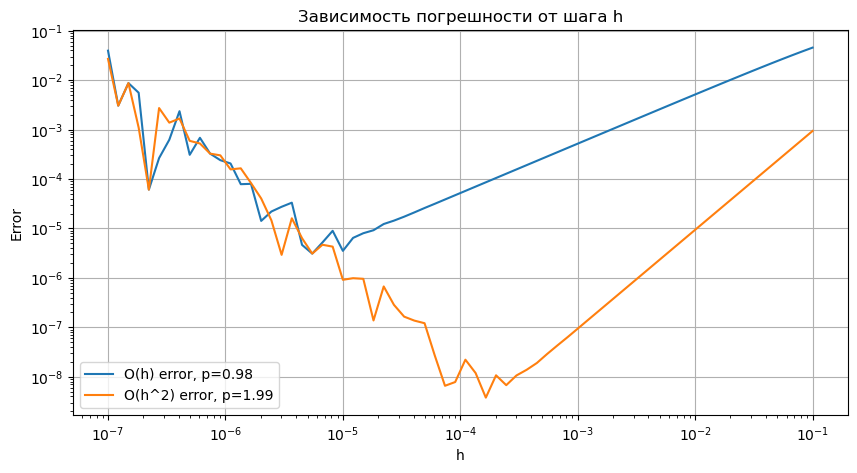

Экспериментальный порядок O(h): 0.9840
Экспериментальный порядок O(h^2): 1.9893


In [2]:
f = lambda x: np.cosh(x)
df2_analytic = lambda x: np.cosh(x)

def df2_order1(f, x, h):
    return (f(x + 2*h) - 2*f(x + h) + f(x)) / (h**2)

def df2_order2(f, x, h):
    return (f(x + h) - 2*f(x) + f(x - h)) / (h**2)

h_values = np.logspace(-1, -7, 70)
x_target = -0.5
h_plot = 0.1
x_range = np.linspace(-0.8, -0.2, 100)

y_analytic = df2_analytic(x_range)
y_order1 = df2_order1(f, x_range, h_plot)
y_order2 = df2_order2(f, x_range, h_plot)

plt.figure(figsize=(10, 5))
plt.plot(x_range, y_analytic,"b--",  label='cosh(x)')
plt.plot(x_range, y_order1, label='O(h)', alpha=0.5)
plt.plot(x_range, y_order2, label='O(h^2)', alpha=0.5)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

err1 = []
err2 = []

for h in h_values:
    e1 = np.abs(df2_order1(f, x_target, h) - df2_analytic(x_target))
    e2 = np.abs(df2_order2(f, x_target, h) - df2_analytic(x_target))
    err1.append(e1)
    err2.append(e2)

p1 = np.polyfit(np.log(h_values)[:30:], np.log(err1)[:30:], 1)[0]
p2 = np.polyfit(np.log(h_values)[:30:], np.log(err2)[:30:], 1)[0]

plt.figure(figsize=(10, 5))
plt.loglog(h_values, err1, label=f'O(h) error, p={p1:.2f}')
plt.loglog(h_values, err2, label=f'O(h^2) error, p={p2:.2f}')
plt.title("Зависимость погрешности от шага h")
plt.xlabel("h")
plt.ylabel("Error")
plt.legend()
plt.grid(True)
plt.show()

print(f"Экспериментальный порядок O(h): {p1:.4f}")
print(f"Экспериментальный порядок O(h^2): {p2:.4f}")

### Задача 2  Численное интегрирование (4 балла)

Вычислить приближенно интеграл 

$$
J=\int_0^{\pi / 2} \ln \sin x \cdot d x
$$


Точное значение интеграла равно $J=-1.0890045$. 

Вам нужно использовать метод, который даст не меньше 6 верных знаков после запятой. Точное значение интеграла, как и функцию `quad`, при вычислении использовать нельзя.

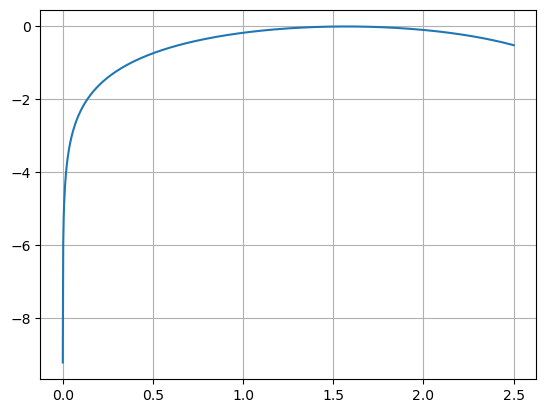

In [3]:
x = np.linspace(0.0001, 2.5, 1000)
y = np.log(np.sin(x))

plt.plot(x, y)
plt.grid(True)
plt.show()

$$ J = \int_0^{\pi/2} \ln(\sin x) dx = \int_0^{\pi/2} \left( \ln(\sin x) - \ln x \right) dx + \int_0^{\pi/2} \ln x \, dx $$
$$ \int_0^{\pi/2} \ln x \, dx =  \frac{\pi}{2} \ln \frac{\pi}{2} - \frac{\pi}{2} $$


In [4]:
def g(x):
    res = np.zeros_like(x)
    mask = x > 0
    res[mask] = np.log(np.sin(x[mask]) / x[mask])
    return res

def simpson(f, a, b, n):
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return (h / 3) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]) + y[-1])

def integrate_runge(f, a, b, eps=1e-6):
    n = 4
    Ih = simpson(f, a, b, n)
    while True:
        n *= 2
        Ih_2 = simpson(f, a, b, n)
        # p=4 для метода Симпсона
        err = np.abs(Ih_2 - Ih) / 15.0
        if err < eps:
            return Ih_2, err, n
        Ih = Ih_2

a, b = 0.0, np.pi / 2
analytical_part = b * np.log(b) - b

numerical_part, err, n_final = integrate_runge(g, a, b, eps=1e-7)

J_approx = analytical_part + numerical_part

print(f"Приближенное значение: {J_approx:.8f}")
print(f"Оценка погрешности: {err:.2e}")

Приближенное значение: -1.08879306
Оценка погрешности: 1.65e-08


### Задача 3  Интерполяция (2 балла)

На отрезке $[2,5]$ для дробно-линейной функции $y(x)=\frac{x-3,5}{x+\sqrt{3}-3,5}$ построить интерполяционный полином в форме Лагранжа на сетке из __экстремумов__ полинома Чебышёва с $n$ нулями на данном отрезке. Оценить погрешность данного метода интерполяции в зависимости от $n$ - число узлов Чебышева.


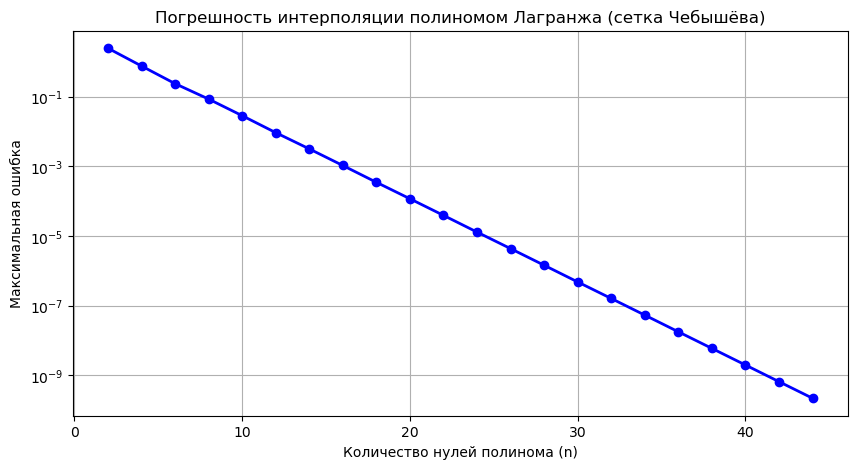

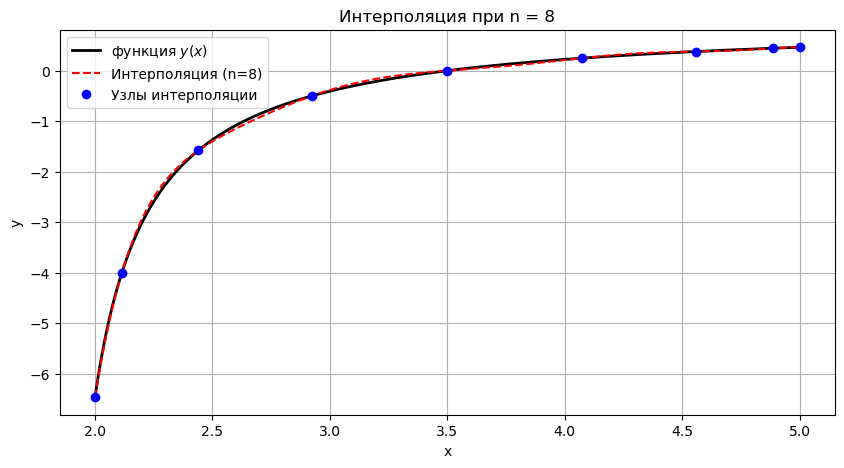

In [5]:
def f(x):
    return (x - 3.5) / (x + np.sqrt(3) - 3.5)

a, b = 2, 5

def chebyshev_extrema(a, b, n):
    k = np.arange(n + 1)
    x_cheb = np.cos(k * np.pi / n)
    return 0.5 * (a + b) + 0.5 * (b - a) * x_cheb

def lagrange_interpolation(x_nodes, y_nodes, x_eval):
    N = len(x_nodes)
    y_eval = np.zeros_like(x_eval, dtype=float)
    for i in range(N):
        li = np.ones_like(x_eval, dtype=float)
        for j in range(N):
            if i != j:
                li *= (x_eval - x_nodes[j]) / (x_nodes[i] - x_nodes[j])
        y_eval += y_nodes[i] * li

    return y_eval

ns = np.arange(2, 45, 2)
errors =[]

x_dense = np.linspace(a, b, 1000)
y_exact = f(x_dense)

for n in ns:
    x_nodes = chebyshev_extrema(a, b, n)
    y_nodes = f(x_nodes)

    y_approx = lagrange_interpolation(x_nodes, y_nodes, x_dense)

    max_err = np.max(np.abs(y_exact - y_approx))
    errors.append(max_err)

plt.figure(figsize=(10, 5))
plt.semilogy(ns, errors, 'bo-', lw=2, markersize=6)
plt.title('Погрешность интерполяции полиномом Лагранжа (сетка Чебышёва)')
plt.xlabel('Количество нулей полинома (n)')
plt.ylabel('Максимальная ошибка')
plt.grid(True)
plt.show()

n_demo = 8
x_nodes_demo = chebyshev_extrema(a, b, n_demo)
y_nodes_demo = f(x_nodes_demo)
y_approx_demo = lagrange_interpolation(x_nodes_demo, y_nodes_demo, x_dense)

plt.figure(figsize=(10, 5))
plt.plot(x_dense, y_exact, 'k-', label='функция $y(x)$', lw=2)
plt.plot(x_dense, y_approx_demo, 'r--', label=f'Интерполяция (n={n_demo})')
plt.plot(x_nodes_demo, y_nodes_demo, 'bo', label='Узлы интерполяции')
plt.title(f'Интерполяция при n = {n_demo}')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

Так как функция аналитична на самом отрезке, использование узлов Чебышёва минимизирует норму узлового многочлена и гарантирует равномерную сходимость. Ошибка убывает экспоненциально с ростом числа узлов $n$.

### Задача 4  Ряды (1 балл)

Вычислить сумму ряда

$$
\sum_{n=1}^{\infty} \frac{n+1}{n^4+n^2+1} \sin (3x)
$$

с точностью $\varepsilon=10^{-6}$. Обоснуйте, почему исходная точность достигнута.

Оценим остаток ряда. Синус всегда <= 1, а знаменатель можно загрубить до n^4. Получается, хвост ряда меньше суммы (n+1)/n^4 = 1/n^3 + 1/n^4. Оцениваем эту сумму через интеграл от N до бесконечности и получаем 1/(2N^2) + 1/(3N^3).
Если взять N = 1000, то погрешность будет примерно 0.5 * 10^-6, что уже меньше нужной нам 10^-6. Ряд сходится быстро (как 1/n^3), достаточно просто просуммировать первую тысячу членов.

In [6]:
n = np.arange(1000.0, 0.0, -1.0)
#считаем флотами в обратном порядке
S = np.sum((n + 1.0) / (n**4.0 + n**2.0 + 1.0) * np.sin(3.0 * n))

print(f"Сумма: {S:.9f}")

Сумма: 0.066098992


In [7]:
n = np.arange(100000.0, 0.0, -1.0)

S = np.sum((n + 1.0) / (n**4.0 + n**2.0 + 1.0) * np.sin(3.0 * n))

print(f"Сумма: {S:.9f}")

Сумма: 0.066098992


### Задача 5  Дискретное преобразование Фурье (1.5 балла)

Сгенерируйте два сигнала: сигнал 1 - синусоидальная волна с частотой 5 Гц, амплитудой 3 и фазовым сдвигом 3; сигнал 2 - синусоидальная волна с частотой 2 Гц, амплитудой 2 и фазовым сдвигом -2. Постройте график суммы сигнала в течение 2 секунд. Сделайте дискретное преобразование Фурье. Как из него "вычленить" исходные сигналы?

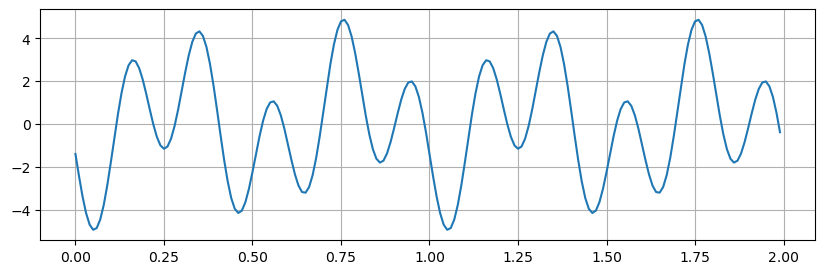

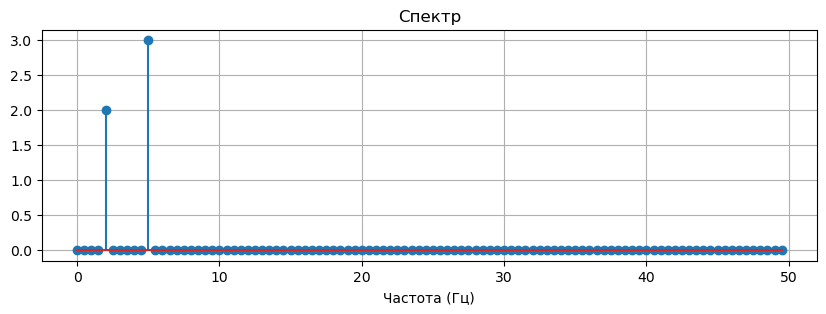

In [9]:
fs = 100.0
t = np.arange(0.0, 2.0, 1.0/fs)

s1 = 3.0 * np.sin(2.0 * np.pi * 5.0 * t + 3.0)
s2 = 2.0 * np.sin(2.0 * np.pi * 2.0 * t - 2.0)
s_sum = s1 + s2

plt.figure(figsize=(10, 3))
plt.plot(t, s_sum)
plt.grid()
plt.show()

N = len(t)
X = np.fft.fft(s_sum)
freqs = np.fft.fftfreq(N, 1.0/fs)

plt.figure(figsize=(10, 3))
plt.stem(freqs[:N//2], 2.0/N * np.abs(X[:N//2]))
plt.title('Спектр')
plt.xlabel('Частота (Гц)')
plt.grid()
plt.show()

Исходные частоты видны на графике модуля спектра, фазовый сдвиг можно узнать из фазы комплексного числа